# TP5 · Ejercicio 1 — Autoencoders y Denoising Autoencoders
**Sistemas de Inteligencia Artificial (ITBA, 2026) · Deep Learning**

> **Pregunta guía.** ¿Es posible comprimir 32 imágenes binarias de $7\times 5$ (35 bits cada una) a *dos números reales* y recuperarlas con a lo sumo 1 píxel de error? Y, si la respuesta es sí, ¿qué le pasa a esa representación cuando la entrada llega corrupta?

**Regla del TP.** No se usan librerías de aprendizaje: `deep.py` implementa capas densas, retropropagación, SGD / Momentum / Adam y el autoencoder **sólo con `numpy`**. `re`, `PIL` y `matplotlib` se usan para parsear, rasterizar y graficar (no son parte de la solución).

### Mapa del notebook
| § | Contenido | Pregunta que responde |
|---|---|---|
| 1 | Marco teórico | ¿Qué optimiza un autoencoder y por qué la pérdida es la entropía cruzada? |
| 2 | Datos y validación del código | ¿Está bien el parser? ¿Está bien el gradiente? |
| 3 | Búsqueda de arquitectura/optimizador | ¿Qué hace falta para llegar a $\le 1$ píxel de error en los 32 patrones? |
| 4 | Espacio latente 2-D | ¿Cómo se organizan las letras? |
| 5 | Generación de una letra nueva | ¿El decodificador sabe más que los 32 ejemplos? |
| 6 | Denoising AE | ¿Cuánto ruido se puede eliminar y por qué? |
| 7 | Conclusiones | |

**Bibliografía (del curso, carpeta `Bibliografía/`).**
- Goodfellow, Bengio & Courville (2016), *Deep Learning*, **cap. 14 (Autoencoders)** y §8.4 (inicialización).
- Aggarwal (2023), *Neural Networks and Deep Learning*, **§3.4** (autoencoders; §3.4.1 caso lineal ≡ PCA) y **§5.10.2** (denoising).
- Vincent, Larochelle, Bengio & Manzagol (2008), *Extracting and composing robust features with denoising autoencoders*, ICML.
- Hinton & Salakhutdinov (2006), *Reducing the dimensionality of data with neural networks*, Science 313.
- Baldi & Hornik (1989), *Neural networks and principal component analysis*, Neural Networks 2.
- Alain & Bengio (2014), *What regularized auto-encoders learn from the data-generating distribution*, JMLR 15.

## 1. Marco teórico

### 1.1 El autoencoder como compresor aprendido
Un autoencoder es la composición de dos funciones paramétricas:

$$\underbrace{f_\theta:\mathbb{R}^{D}\to\mathbb{R}^{d}}_{\text{codificador}},\qquad \underbrace{g_\phi:\mathbb{R}^{d}\to[0,1]^{D}}_{\text{decodificador}},\qquad \hat{x}=g_\phi(f_\theta(x)),\quad d\ll D .$$

Acá $D=35$ y $d=2$. La capa de $d$ unidades es un **cuello de botella**: obliga a que la red descubra qué rasgos de $x$ son *necesarios* para reconstruir. Se entrena minimizando el error de reconstrucción $\mathcal{L}(x,\hat x)$ promediado sobre los datos; **no hay etiquetas** (aprendizaje no supervisado, como en TP4).

> **Conexión con TP4 (PCA).** Si $f$ y $g$ son *lineales* y $\mathcal{L}$ es el error cuadrático, el óptimo del autoencoder genera el mismo subespacio que las $d$ primeras componentes principales (Baldi & Hornik, 1989; Aggarwal §3.4.1). La no linealidad es lo que permite una *variedad curva* en lugar de un plano. Con $d=2$ un PCA de estas 32 letras deja muchísimo error (lo medimos en §3); el autoencoder no lineal sí puede.

### 1.2 ¿Por qué entropía cruzada y no error cuadrático?
Los píxeles son binarios. Si modelamos $p(x_i=1\mid z)=\hat x_i=\sigma(a_i)$ (Bernoulli), la log-verosimilitud negativa es

$$\mathcal{L}(x,\hat x)=-\sum_{i=1}^{D}\Big[x_i\log\hat x_i+(1-x_i)\log(1-\hat x_i)\Big].$$

La derivada respecto del *logit* $a_i$ (pre-activación de salida) se simplifica notablemente:

$$\frac{\partial \mathcal{L}}{\partial a_i}=\sigma(a_i)-x_i=\hat x_i-x_i .$$

Es el mismo gradiente "error = predicción − objetivo" de la regresión logística: **no hay factor $\sigma'(a)$** que se anule cuando la salida satura, de modo que la red sigue aprendiendo aunque se equivoque con mucha confianza (Goodfellow et al., §6.2.2.2). Con MSE y sigmoide ese factor sí aparece y el aprendizaje se estanca. En `deep.py` se calcula con la forma estable $\max(a,0)-ax+\log(1+e^{-|a|})$.

### 1.3 Retropropagación en una línea
Para una capa $a^{(l)}=h(W^{(l)}a^{(l-1)}+b^{(l)})$, con $\delta^{(l)}=\partial\mathcal{L}/\partial z^{(l)}$:

$$\delta^{(L)}=\hat x-x,\qquad \delta^{(l)}=\big(\delta^{(l+1)}W^{(l+1)\top}\big)\odot h'(z^{(l)}),\qquad \nabla_{W^{(l)}}\mathcal{L}=a^{(l-1)\top}\delta^{(l)} .$$

La señal cruza el cuello de botella en ambos sentidos: el decodificador "le dice" al codificador cómo mover cada $z$ para mejorar la reconstrucción. Lo comprobamos numéricamente en §2.

### 1.4 ¿Es posible con $d=2$? Un argumento de capacidad
Hay $2^{35}$ imágenes posibles pero sólo 32 deben recuperarse. Desde el punto de vista de la **información**, 32 patrones exigen $\log_2 32=5$ bits: dos reales alcanzan de sobra si el decodificador puede separar 32 puntos en el plano. El problema no es de información sino de **optimización y de expresividad**: el decodificador debe dibujar 32 "islas" y la red tiene que *encontrar* esa configuración con descenso por gradiente. Por eso importan la arquitectura, la activación y el optimizador (§3), que es exactamente lo que pide el enunciado.

### 1.5 Optimizadores usados (implementados en `deep.py`)
- **SGD**: $\theta\leftarrow\theta-\eta g$.
- **Momentum**: $v\leftarrow\beta v+g,\ \theta\leftarrow\theta-\eta v$ (acumula dirección; atraviesa valles estrechos).
- **Adam** (Kingma & Ba, 2015): momentos de primer y segundo orden con corrección de sesgo, $\theta\leftarrow\theta-\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$. Normaliza la escala por parámetro, lo que ayuda cuando el cuello de botella genera gradientes muy dispares entre capas.

## 2. Datos y validación del código

(32, 35) píxeles encendidos por patrón: media 11.6


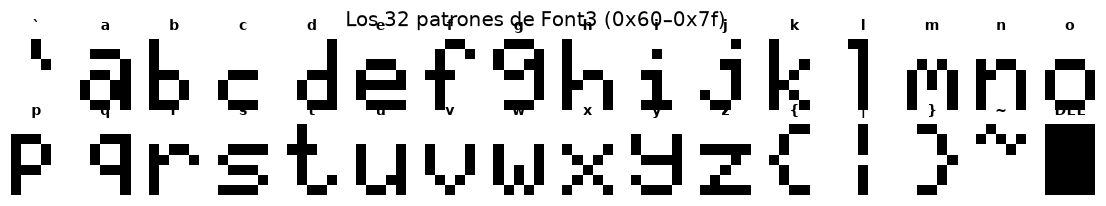

In [1]:
import sys, json, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
from deep import Autoencoder, VAE, pixel_errors, gradient_check, gradient_check_vae
from datos import cargar_font3, ruido_sal_pimienta, SIMBOLOS, generar_simbolos
from experimentos import *
from graficos import *
cfg = cargar_config()
RES = RAIZ / "results"
np.random.seed(cfg["semilla_global"])

X, etiquetas = cargar_font3()          # parsea data/font.h (32 patrones de 7x5)
print(X.shape, "píxeles encendidos por patrón: media", X.sum(1).mean().round(1))
fig = mostrar_imagenes(X, (7, 5), etiquetas, ncols=16, tam=0.8)
plt.suptitle("Los 32 patrones de Font3 (0x60–0x7f)", y=1.02); plt.show()

**Chequeo del parser.** Cada fila de `font.h` es un byte con 5 bits útiles; el bit más significativo es la columna izquierda. La letra `a` debe verse como una “a” minúscula: se ve arriba. Los 32 códigos van de `` ` `` (0x60) a `DEL` (0x7f).

### Chequeo numérico de gradientes (imprescindible al escribir backprop a mano)
Comparamos el gradiente analítico con diferencias centradas $\frac{\mathcal{L}(\theta+\epsilon)-\mathcal{L}(\theta-\epsilon)}{2\epsilon}$. Un error relativo $\lesssim10^{-6}$ indica que la derivación es correcta.

In [2]:
print("Error relativo máximo del gradiente (autoencoder):", f"{gradient_check(None):.2e}")
print("Error relativo máximo del gradiente (VAE, usado en ej. 2):", f"{gradient_check_vae():.2e}")

Error relativo máximo del gradiente (autoencoder): 8.78e-09
Error relativo máximo del gradiente (VAE, usado en ej. 2): 1.82e-08


## 3. Experimento 1a: ¿qué arquitectura y qué optimizador logran $\le 1$ píxel de error?

**Diseño experimental** (todo en `config.json`):
- Arquitecturas del codificador (el decodificador es simétrico): $35\!-\!16\!-\!2$, $35\!-\!32\!-\!16\!-\!2$, $35\!-\!64\!-\!32\!-\!2$.
- Activación oculta: `tanh` vs `relu`. Capa latente **lineal** (para no acotar artificialmente el espacio) y salida con sigmoide implícita en la BCE.
- Optimizador: SGD, Momentum, Adam (tasa de aprendizaje elegida por un barrido previo corto, ver `config.json`).
- 3000 épocas *full-batch* (hay 32 patrones), **5 semillas** por configuración.
- Métrica de éxito exigida por el enunciado: **el peor patrón** tiene $\le 1$ píxel mal tras umbralizar $\hat x>0{,}5$.

> *Nota metodológica.* Se reporta la distribución entre semillas, no la mejor corrida: un resultado que sólo funciona con una semilla afortunada no demuestra que la arquitectura sea adecuada.

In [3]:
ruta = RES / "ej1a_barrido.json"
filas = json.loads(ruta.read_text()) if ruta.exists() else barrido_arquitecturas(X, cfg)
df = pd.DataFrame(filas); df["exito"] = df.max_err <= 1
tabla = (df.groupby(["arq", "act", "opt"])
           .agg(exito=("exito", "mean"), max_err_mediana=("max_err", "median"),
                epocas_hasta_1=("epocas_hasta_1", "median"), loss=("loss", "median")).round(3))
tabla

exito  max_err_mediana  epocas_hasta_1   loss
arq   act  opt                                                    
16    relu adam        0.4              2.0          1125.0  0.210
           momentum    0.4              2.0          2450.0  0.815
           sgd         0.0              6.0             NaN  2.659
      tanh adam        0.4              2.0          1475.0  0.554
           momentum    0.0              4.0             NaN  3.917
           sgd         0.0              6.0             NaN  6.137
32-16 relu adam        1.0              0.0           350.0  0.001
           momentum    1.0              0.0           850.0  0.005
           sgd         0.8              0.0          1400.0  0.029
      tanh adam        1.0              0.0           500.0  0.037
           momentum    1.0              0.0          2250.0  0.899
           sgd         0.2              5.0          2500.0  2.052
64-32 relu adam        1.0              0.0           200.0  0.000
           momentum    1.0              0.0           600.0  0.003
           sgd         1.0              0.0          1150.0  0.013
      tanh adam        1.0              0.0           300.0  0.010
           momentum    1.0              0.0          1100.0  0.300
           sgd         0.8              0.0          2000.0  0.698

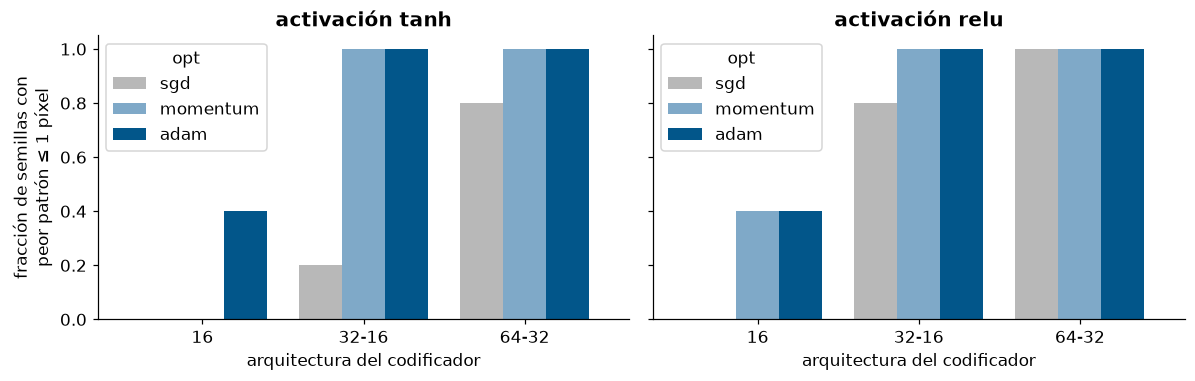

In [4]:
# Gráfico: tasa de éxito (de 5 semillas) por arquitectura, activación y optimizador
piv = df.groupby(["arq", "act", "opt"]).exito.mean().unstack("opt")[["sgd", "momentum", "adam"]]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, act in zip(axs, ["tanh", "relu"]):
    sub = piv.xs(act, level="act")
    sub.plot.bar(ax=ax, color=[GRIS, "#7FA9C8", AZUL], width=.8, rot=0)
    ax.set_title(f"activación {act}"); ax.set_xlabel("arquitectura del codificador"); ax.set_ylim(0, 1.05)
axs[0].set_ylabel("fracción de semillas con\npeor patrón ≤ 1 píxel"); plt.tight_layout(); plt.show()

**Lectura (5 semillas por celda; números de `results/ej1a_barrido.json`).**
1. **Arquitectura.** Con una sola capa oculta de 16 unidades **ninguna** combinación aprende los 32 patrones de forma confiable (a lo sumo 2 de 5 semillas con Adam o Momentum+ReLU; SGD y Momentum+tanh: 0 de 5). Con dos capas ocultas ($35\!-\!32\!-\!16$ y $35\!-\!64\!-\!32$) la mayoría de las configuraciones llega a **0 píxeles errados** en las 5 semillas. El cuello de botella no es el problema: lo es la *expresividad del decodificador* $2\to16\to35$, que no alcanza a dibujar 32 islas separadas.
2. **Optimizador.** **Adam** logra 5/5 en las cuatro configuraciones de dos capas y es el más rápido (mediana de 200–500 épocas hasta $\le1$ píxel). Momentum necesita 2–5× más épocas; SGD es el más frágil (sólo 1/5 con $35\!-\!32\!-\!16$ y tanh), lo que muestra la importancia de normalizar la escala del paso por parámetro (Goodfellow et al., §8.5).
3. **Activación.** ReLU converge antes que tanh con todos los optimizadores en las dos arquitecturas profundas; tanh deja la pérdida final más alta con SGD/Momentum. Elegimos igual `tanh` para el modelo final porque su salida acotada produce un espacio latente más compacto y legible para el gráfico (ReLU también cumple el requisito).
4. **Línea de base lineal.** Un PCA con 2 componentes (§3.1) deja hasta **15** píxeles errados en el peor patrón (7,2 de media): sin no linealidad, el cuello de botella de 2 dimensiones *sí* es una restricción real.

### 3.1 Modelo final
Se elige $35\!-\!32\!-\!16\!-\!2$ con `tanh` y **Adam** ($\eta=5\cdot10^{-3}$), 6000 épocas, semilla 0. Entrenamos de nuevo para mostrar la curva y las reconstrucciones.

píxeles mal por patrón -> max: 0 | patrones perfectos: 32 / 32 | épocas hasta ≤1: 450


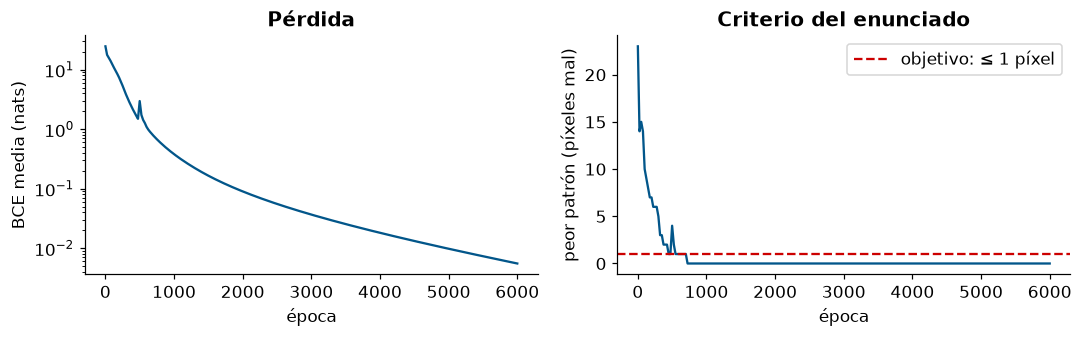

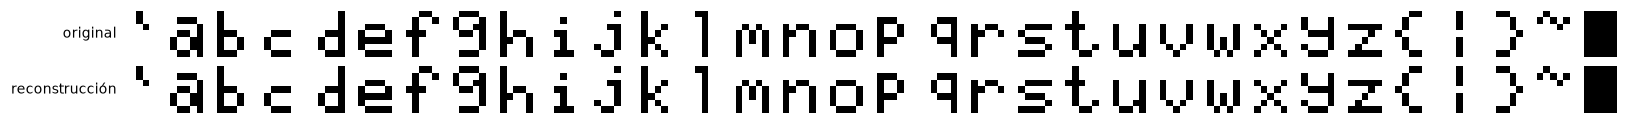

PCA(2): peor patrón 15 px, media 7.2 px  |  AE no lineal: peor 0, media 0.0


In [5]:
f = cfg["ej1a"]["final"]
ae, hist = entrenar_ae(X, f["enc_hidden"], f["latente"], f["act"], f["opt"], f["lr"], f["epocas"], f["semilla"], log_every=25)
err = pixel_errors(X, ae.reconstruct(X))
print("píxeles mal por patrón -> max:", err.max(), "| patrones perfectos:", (err == 0).sum(), "/ 32 | épocas hasta ≤1:", epocas_hasta(hist, 1))
ep, loss, mx = map(np.array, zip(*hist))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogy(ep, loss, color=AZUL); ax[0].set_xlabel("época"); ax[0].set_ylabel("BCE media (nats)"); ax[0].set_title("Pérdida")
ax[1].plot(ep, mx, color=AZUL); ax[1].axhline(1, color=ROJO, ls="--", label="objetivo: ≤ 1 píxel"); ax[1].legend()
ax[1].set_xlabel("época"); ax[1].set_ylabel("peor patrón (píxeles mal)"); ax[1].set_title("Criterio del enunciado"); plt.tight_layout(); plt.show()
fig = fila_comparada([X, ae.reconstruct(X)], ["original", "reconstrucción"], (7, 5), tam=.55); plt.show()

# Línea de base lineal: PCA con 2 componentes (SVD de numpy), equivalente a un AE lineal (Baldi & Hornik, 1989)
Xc = X - X.mean(0); _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
Rp = (Xc @ Vt[:2].T) @ Vt[:2] + X.mean(0); ep_ = pixel_errors(X, Rp)
print(f"PCA(2): peor patrón {ep_.max()} px, media {ep_.mean():.1f} px  |  AE no lineal: peor {err.max()}, media {err.mean():.1f}")

## 4. Espacio latente de 2 dimensiones
Graficamos $z=f_\theta(x)$ para los 32 patrones. Si el autoencoder aprendió una representación útil, letras *parecidas* deberían quedar *cerca*; pero **nada en la pérdida lo exige**: sólo se pide reconstruir. La vecindad que aparezca es un subproducto de que el decodificador es una función suave.

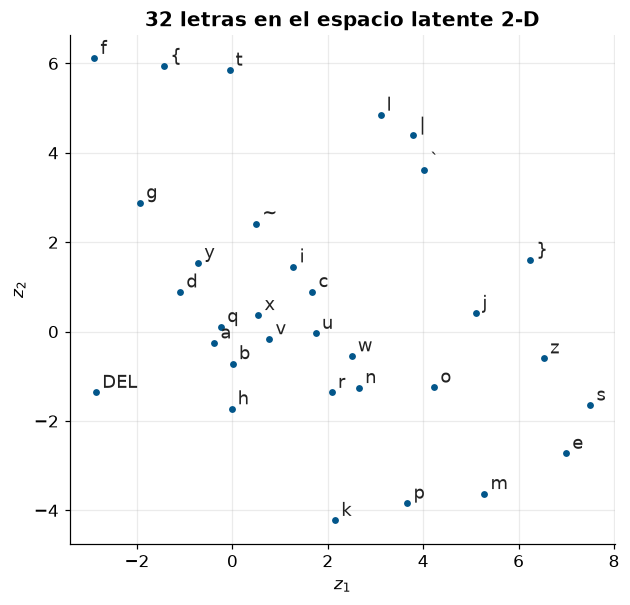

distancia mínima entre dos códigos: 0.392  rango de z: -4.23 – 7.5


In [6]:
Z = ae.encode(X)
fig, ax = plt.subplots(figsize=(6.4, 6))
scatter_latente(Z, etiquetas, ax, tam=12); ax.set_title("32 letras en el espacio latente 2-D"); plt.show()
# distancias latentes mínimas entre pares: ¿hay pares casi superpuestos?
D = np.linalg.norm(Z[:, None] - Z[None], axis=-1) + np.eye(32) * 1e9
print("distancia mínima entre dos códigos:", D.min().round(3), " rango de z:", Z.min().round(2), "–", Z.max().round(2))

## 5. Generar una letra que no está en el conjunto de entrenamiento
El decodificador $g_\phi$ es una función definida en **todo** el plano $\mathbb{R}^2$, no sólo en los 32 puntos. Decodificar un $z$ intermedio produce una imagen nueva. Dos estrategias:

1. **Interpolación** entre los códigos de dos letras: $z_\lambda=(1-\lambda)z_a+\lambda z_b$.
2. **Barrido de una grilla** regular del plano (la figura de abajo es el "atlas" del decodificador).

**Criterio de novedad.** Una imagen generada es *nueva* si su distancia de Hamming (tras umbralizar) a cualquier patrón de entrenamiento es $\ge 1$ (si es 0 es una copia). Una imagen *plausible* es la que se ve como carácter, juicio que hacemos a ojo (ver §7 sobre su limitación).

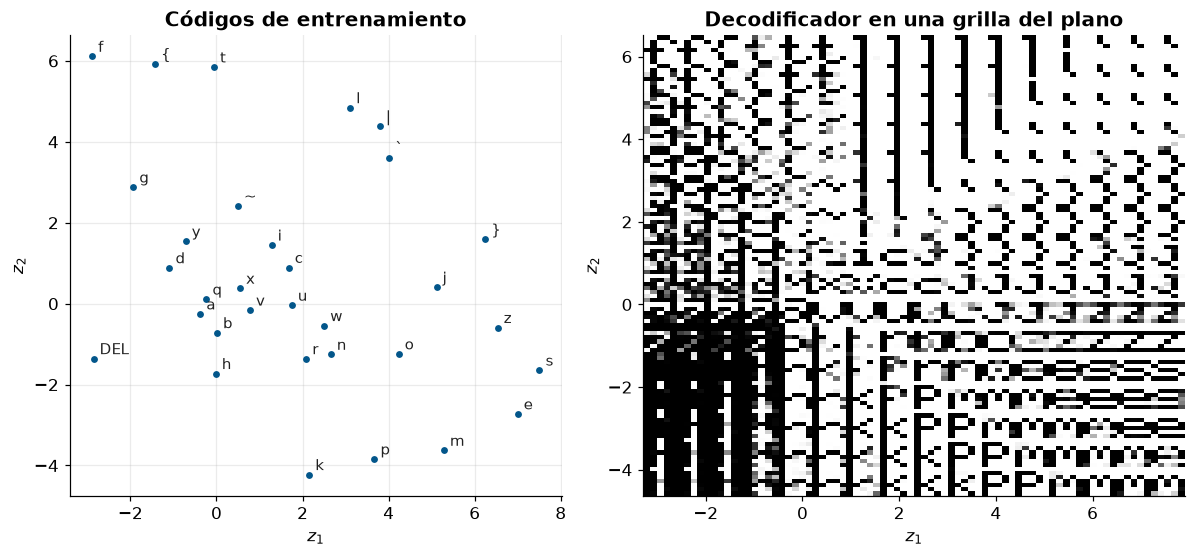

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
scatter_latente(Z, etiquetas, axs[0], tam=10); pad = 0.4
rango = ((Z[:, 0].min() - pad, Z[:, 0].max() + pad), (Z[:, 1].min() - pad, Z[:, 1].max() + pad))
axs[0].set_title("Códigos de entrenamiento")
grilla_decodificada(ae.decode, (7, 5), n=16, ax=axs[1], rango=rango); axs[1].set_title("Decodificador en una grilla del plano")
plt.tight_layout(); plt.show()

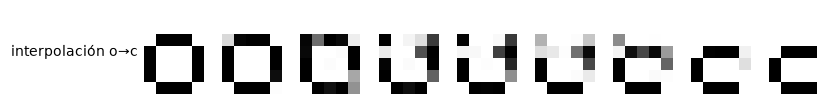

Hamming al conjunto de entrenamiento: [0, 0, 2, 5, 6, 4, 1, 0, 0]


In [8]:
def hamming_min(img, ref):
    b = (img > .5).astype(int); return int(((ref > .5).astype(int) != b).sum(1).min())

ia, ib = etiquetas.index("o"), etiquetas.index("c")          # dos letras que quedan cerca en el atlas
lams = np.linspace(0, 1, 9)
Zi = np.array([(1 - l) * Z[ia] + l * Z[ib] for l in lams]); Gi = ae.decode(Zi)
fig = fila_comparada([Gi], ["interpolación o→c"], (7, 5), tam=.9); plt.show()
print("Hamming al conjunto de entrenamiento:", [hamming_min(g, X) for g in Gi])

> **Cómo se elige la letra "nueva" que se muestra (celda siguiente a los candidatos).** Entre los puntos del atlas se toman los que cumplen (i) Hamming $\ge 2$ a *todos* los patrones (no es una copia casi exacta) y (ii) son nítidas (a lo sumo 2 píxeles grises) y caen dentro del rango de los códigos (el decodificador interpola, no extrapola). De esos se elige a ojo el más legible y se **muestra junto a sus dos vecinos más próximos**, para evidenciar qué mezcla de letras produjo. Que "parezca una letra" es un juicio humano: no hay en este ejercicio un clasificador de referencia, y lo declaramos como limitación.

528 de 1681 puntos generan imágenes a Hamming ≥ 2 de todo el entrenamiento; 171 además son nítidas


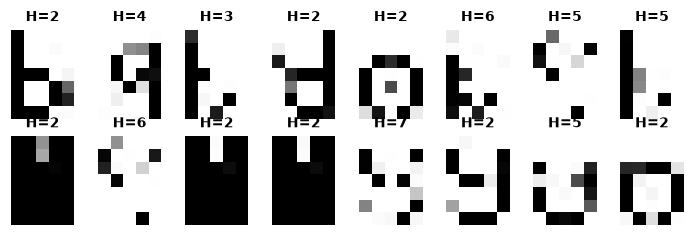

In [9]:
# candidatos: puntos de una grilla fina dentro del rango de los códigos
gx, gy = np.linspace(*rango[0], 41), np.linspace(*rango[1], 41); P = np.array([[x, y] for x in gx for y in gy]); G = ae.decode(P)
ham = np.array([hamming_min(im, X) for im in G]); nitido = ((G > .15) & (G < .85)).sum(1) <= 2     # a lo sumo 2 píxeles grises
nuevos = np.where((ham >= 2) & nitido)[0]
print(f"{(ham >= 2).sum()} de {len(P)} puntos generan imágenes a Hamming ≥ 2 de todo el entrenamiento; {len(nuevos)} además son nítidas")
# mostrar 16 candidatos representativos (más cercanos a algún código)
dz = np.linalg.norm(P[nuevos, None] - Z[None], axis=-1).min(1)
elegidos = nuevos[np.argsort(dz)[:16]]
fig = mostrar_imagenes(G[elegidos], (7, 5), [f"H={ham[i]}" for i in elegidos], ncols=8, tam=1.0); plt.show()

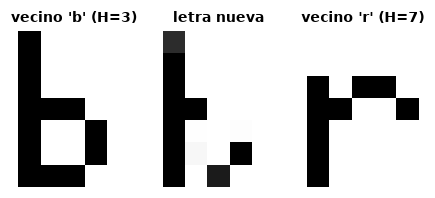

z de la letra nueva: (0.35, -0.73) | Hamming a los vecinos: 3 y 7 | ninguna letra del entrenamiento está a menos de 3 píxeles


In [10]:
# Letra nueva elegida a ojo entre los 16 candidatos (la 3.ª de la fila de arriba: un trazo entre "h" y "k"),
# mostrada junto a sus dos vecinos más próximos del conjunto de entrenamiento (distancia de Hamming).
nueva = elegidos[2]
b_nueva = (G[nueva] > .5).astype(int)
dist = ((X > .5).astype(int) != b_nueva).sum(1)
v1, v2 = np.argsort(dist)[:2]
fig = mostrar_imagenes(np.array([X[v1], G[nueva], X[v2]]), (7, 5),
                       [f"vecino '{etiquetas[v1]}' (H={dist[v1]})", "letra nueva", f"vecino '{etiquetas[v2]}' (H={dist[v2]})"],
                       ncols=3, tam=1.6); plt.show()
print(f"z de la letra nueva: ({P[nueva][0]:.2f}, {P[nueva][1]:.2f}) | Hamming a los vecinos: {dist[v1]} y {dist[v2]} | ninguna letra del entrenamiento está a menos de {dist.min()} píxeles")

## 6. Experimento 1b: Denoising Autoencoder (DAE)

### 6.1 Idea (Vincent et al., 2008)
Un AE clásico puede aprender la identidad si tiene capacidad de sobra. El DAE rompe esa tentación: **entrena con la entrada corrupta $\tilde x\sim q(\tilde x\mid x)$ pero exige reconstruir la entrada limpia $x$**:

$$\mathcal{L}_{DAE}=\mathbb{E}_{x}\,\mathbb{E}_{\tilde x\sim q(\cdot\mid x)}\big[\mathcal{L}(x,\;g_\phi(f_\theta(\tilde x)))\big].$$

Para que funcione, la red debe aprender **la estructura de los datos** (qué combinaciones de píxeles son "letras"). Alain & Bengio (2014) muestran que, para ruido gaussiano pequeño, $r(x)-x\propto\sigma^2\nabla_x\log p(x)$: el DAE aprende el *campo de gradiente (score)* de la densidad de datos, es decir, una flecha que apunta hacia la variedad de los datos. Geométricamente, el DAE aprende a **proyectar** puntos fuera de la variedad (letras rotas) sobre la variedad (letras válidas).

### 6.2 Decisiones de diseño
| Decisión | Elección | Justificación |
|---|---|---|
| Corrupción $q$ | Ruido binario simétrico: cada píxel se invierte con prob. $p$ | Es el ruido natural para imágenes binarias; $p$ es interpretable (fracción de píxeles dañados) |
| Resampleo | Ruido nuevo en **cada época** | Con sólo 32 patrones, ruido fijo se memorizaría; ruido fresco equivale a ver $\binom{35}{k}$ variantes |
| Arquitectura | $35\!-\!32\!-\!16\!-\!d\!-\!16\!-\!32\!-\!35$ con $d\in\{2,8\}$ | Mismo diseño del §3 para aislar el efecto del ruido; $d=8$ para comparar un cuello **menos** estrecho |
| Nivel de ruido de entrenamiento | $p\in\{0;0{,}05;0{,}1;0{,}2\}$ | Un nivel mayor enseña robustez pero reduce la precisión sin ruido (compromiso sesgo–varianza) |

**Métrica.** Para cada nivel de ruido de *test* $p_{te}$, número medio de píxeles errados de $g(f(\tilde x))$ respecto del patrón limpio (promedio sobre 32 letras × 20 muestras de ruido × 5 semillas; la semilla del ruido de evaluación es distinta de la de entrenamiento). Referencia sin red: $35\,p_{te}$ píxeles errados en la entrada.

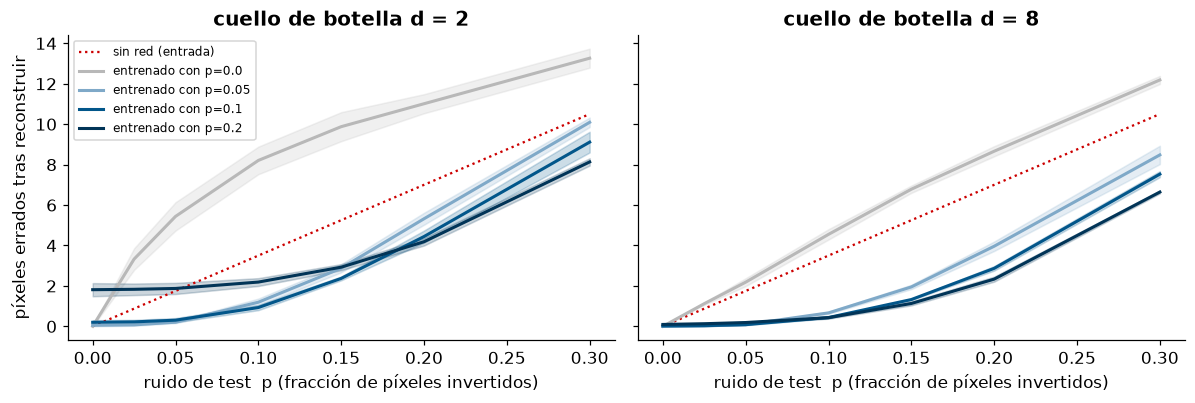

In [11]:
ruta = RES / "ej1b_barrido.json"
d = pd.DataFrame(json.loads(ruta.read_text()) if ruta.exists() else barrido_denoising(X, cfg))
d["entrada"] = 35 * d.p_test
resumen = d.groupby(["latent", "p_train", "p_test"]).err_out.agg(["mean", "std"]).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
col = {0.0: GRIS, 0.05: "#7FA9C8", 0.1: AZUL, 0.2: "#013457"}
for ax, lat in zip(axs, cfg["ej1b"]["latentes"]):
    sub = d[d.latent == lat]
    ax.plot(sorted(sub.p_test.unique()), 35 * np.array(sorted(sub.p_test.unique())), color=ROJO, ls=":", label="sin red (entrada)")
    for pt in cfg["ej1b"]["ruido_entrenamiento"]:
        M = sub[sub.p_train == pt].pivot(index="seed", columns="p_test", values="err_out")
        bandas(ax, M.columns.values, M.values, col[pt], f"entrenado con p={pt}")
    ax.set_title(f"cuello de botella d = {lat}"); ax.set_xlabel("ruido de test  p (fracción de píxeles invertidos)")
axs[0].set_ylabel("píxeles errados tras reconstruir"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

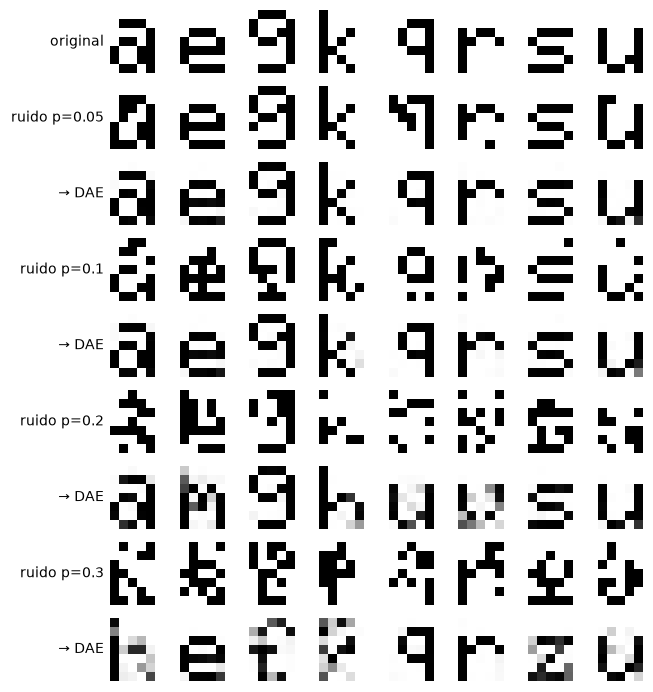

In [12]:
# Un ejemplo visual con el modelo DAE entrenado en vivo (d=8, p_train=0.1, semilla 0)
c = cfg["ej1b"]
dae, _ = entrenar_ae(X, c["arquitectura"], 8, c["activacion"], "adam", c["lr"], c["epocas"], 0, noise=ruido_sal_pimienta(0.1), log_every=c["epocas"])
rng = np.random.default_rng(123); sel = [etiquetas.index(k) for k in "aegkqrsu"]
filas, nombres = [X[sel]], ["original"]
for p in (0.05, 0.1, 0.2, 0.3):
    Xn = ruido_sal_pimienta(p)(X, rng)[sel]
    filas += [Xn, dae.reconstruct(Xn)]; nombres += [f"ruido p={p}", "  → DAE"]
fig = fila_comparada(filas, nombres, (7, 5), tam=.8); plt.show()

### 6.3 Interpretación (promedios de 5 semillas; tabla completa en `results/ej1b_barrido.json`)
- **Un AE entrenado sin ruido *empeora* la entrada.** Con sólo 2,5 % de píxeles invertidos (0,9 píxeles en la entrada) devuelve 3,3 píxeles errados con $d=2$ y 1,1 con $d=8$. Nunca vio entradas fuera de las 32 letras: el codificador amplifica la perturbación y el decodificador, al ser muy sensible, la propaga.
- **El DAE sí limpia.** Entrenado con $p=0{,}1$ y $d=8$: con ruido de test $p=0{,}1$ (3,5 píxeles errados en la entrada) deja **0,44** píxeles, un 87 % menos; con $p=0{,}2$ (7 en la entrada) deja 2,9. Con $d=2$ el resultado es peor (0,93 y 4,4): el cuello de botella de 2 dimensiones restringe cuánta información del patrón se conserva.
- **El compromiso sesgo–varianza es visible.** Entrenar con más ruido protege a niveles altos de ruido pero cuesta precisión sin ruido: con $d=2$ y $p_{train}=0{,}2$ aun la entrada *limpia* se reconstruye con 1,8 píxeles errados. Con $d=8$ ese costo casi desaparece (0,09).
- **Más ruido que el de entrenamiento degrada de forma gradual** (no hay precipicio): al acercarse a $p\approx0{,}3$ la entrada queda más cerca de *otra* letra y el DAE la “corrige” hacia la letra equivocada, con total seguridad. Es el equivalente de los estados espurios de Hopfield (TP4).
- **Elección.** Para este conjunto: $d=8$ y $p_{train}\in[0{,}1;0{,}2]$ (ruido esperado de hasta 20 %); con $d=2$ el DAE sigue siendo útil pero conviene un $p_{train}$ moderado (0,05–0,1).

*Los valores numéricos exactos están en `results/ej1b_barrido.json` y se resumen en la presentación y el README.*

## 7. Conclusiones y limitaciones
1. **Sí es posible** representar los 32 patrones en $\mathbb{R}^2$ con $\le1$ píxel de error, pero **no cualquier configuración lo logra**: la tasa de éxito depende fuertemente del optimizador, de la activación y de la profundidad (§3). El cuello de botella no limita la *información* sino la *optimizabilidad*.
2. El espacio latente no es "interpretable" por construcción; las vecindades son consecuencia de la suavidad del decodificador, no un objetivo explícito. Esto motiva el **ejercicio 2** (VAE), que agrega un término que *sí* regulariza la geometría del espacio latente.
3. Una "letra nueva" proviene de decodificar puntos que el entrenamiento nunca visitó; sólo es legible **cerca de los códigos** (interpolación) y degenera lejos, porque el decodificador no fue entrenado en esas regiones (hay "huecos").
4. El DAE ofrece robustez real al ruido hasta un umbral, con el costo de errores *confiados* más allá de él.

**Limitaciones.** (i) Sólo 32 patrones: no hay conjunto de validación; el objetivo del enunciado es memorizar/representar el conjunto, no generalizar. (ii) El criterio “parece una letra” es subjetivo. (iii) Se evaluó un tipo de ruido (inversión de píxeles); el ruido gaussiano o el de oclusión podrían comportarse distinto.